## Setup and Dependencies

In [1]:
%pip install langchain openai tiktoken langchain-openai python-dotenv langgraph genson


[notice] A new release of pip available: 22.3.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Core Implementation

### Loading Environment variables

In [2]:
import os
import getpass
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

def get_key():
    """Get OpenAI API key from .env file, environment, or user input."""
    # Clear any cached API key
    if 'OPENAI_API_KEY' in os.environ:
        del os.environ['OPENAI_API_KEY']

    # Load environment variables from .env file (force reload)
    load_dotenv(override=True)

    api_key = os.getenv('OPENAI_API_KEY')
    if not api_key:
        api_key = getpass.getpass('Enter your OpenAI API key: ')
        os.environ['OPENAI_API_KEY'] = api_key

    # Verify key format
    if api_key and not api_key.startswith('sk-'):
        print("⚠️  Warning: API key doesn't start with 'sk-'")

    print(f"✅ API key loaded (ends with: ...{api_key[-10:] if api_key else 'None'})")
    return api_key

# Set up API key
get_key()
print("API keys configured")

✅ API key loaded (ends with: ...cmKxGpLUIA)
API keys configured


## Load Mini Questions (Module E)

In [3]:
# Load module data
import json, pprint

PATH = "mini_modules/working/module_e.json"
with open(PATH, "r", encoding="utf-8") as f:
    module_data = json.load(f)

mini_script = module_data["questions"]
module_info = module_data["module"]
module_diagnostic_criteria = module_data["diagnosticCriteria"]

# Prepare questions dictionary for easy access
questions = {q["id"]: q for q in mini_script}

print(f"Loaded {len(mini_script)} questions for Module {module_info['id']}: {module_info['name']}\n")

for i, q in enumerate(mini_script[:2], start=1):
    print(f"{i}. {q['id']}: {q['prompt']}\n")

# Branching logic retrieval function
def show_branches(qid: str):
    if qid not in questions:
        raise KeyError(f"{qid!r} not found")
    next = questions[qid].get("next", {})
    print(f"Branching for {qid}:")
    pprint.pp(next)

# Example: inspect the first question’s branches
show_branches("E1")

Loaded 6 questions for Module E: Agoraphobia

1. E1: Do you feel anxious or uneasy in places or situations where help might not be available or escape difficult if you had a panic-like or embarrassing symptom, such as being in a crowd or queue, in an open space or crossing a bridge, in an enclosed space, when alone away from home, when alone at home, or traveling in a bus, train, car, or using public transportation?

2. E2: Do these situations almost always bring on fear or anxiety?

Branching for E1:
{'yes': 'E2', 'no': 'END_MODULE'}


In [4]:
import json
import pprint
from typing import Dict, Any, Optional, List
from pydantic import BaseModel, Field


class Question(BaseModel):
    id: str
    prompt: str
    next: Optional[Dict[str, Any]] = Field(default_factory=dict)

    class Config:
        extra = "allow"  # Allow additional fields that might be in the JSON


class ModuleInfo(BaseModel):
    id: str
    name: str

    class Config:
        extra = "allow"


class ModuleLoader(BaseModel):
    questions: List[Question]
    module: ModuleInfo
    diagnostic_criteria: Optional[Dict[str, Any]] = Field(alias="diagnosticCriteria", default=None)

    # Computed field for easy question access
    _questions_dict: Dict[str, Question] = {}

    class Config:
        extra = "allow"
        validate_by_name = True  # Allows both snake_case and camelCase

    def __init__(self, **data):
        super().__init__(**data)
        # Build questions dictionary after initialization
        self._questions_dict = {q.id: q for q in self.questions}

    @classmethod
    def from_file(cls, file_path: str) -> "ModuleLoader":
        """Load module data from JSON file"""
        with open(file_path, "r", encoding="utf-8") as f:
            data = json.load(f)
        return cls(**data)

    def get_question(self, qid: str) -> Question:
        """Get question by ID"""
        if qid not in self._questions_dict:
            raise KeyError(f"{qid!r} not found")
        return self._questions_dict[qid]

    def show_branches(self, qid: str) -> None:
        """Display branching logic for a question"""
        question = self.get_question(qid)
        print(f"Branching for {qid}:")
        pprint.pp(question.next)

    def print_summary(self, num_questions: int = 2) -> None:
        """Print module summary and first few questions"""
        print(f"Loaded {len(self.questions)} questions for Module {self.module.id}: {self.module.name}\n")

        for i, q in enumerate(self.questions[:num_questions], start=1):
            print(f"{i}. {q.id}: {q.prompt}\n")


# Usage example
PATH = "mini_modules/working/module_e.json"

# Load the module
module_e = ModuleLoader.from_file(PATH)

# Print summary
module_e.print_summary()

# Show branches for first question
module_e.show_branches("E1")

Loaded 6 questions for Module E: Agoraphobia

1. E1: Do you feel anxious or uneasy in places or situations where help might not be available or escape difficult if you had a panic-like or embarrassing symptom, such as being in a crowd or queue, in an open space or crossing a bridge, in an enclosed space, when alone away from home, when alone at home, or traveling in a bus, train, car, or using public transportation?

2. E2: Do these situations almost always bring on fear or anxiety?

Branching for E1:
{'yes': 'E2', 'no': 'END_MODULE'}


## State class for Langgraph's State graph

In [5]:
from typing import Dict, Any, Optional, List, TypedDict, Annotated, Sequence, Literal
from langgraph.graph import MessagesState
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field
from langgraph.channels import BinaryOperatorAggregate
import operator

class InterviewState(BaseModel):
    messages: Annotated[Sequence[BaseMessage], add_messages] = Field(default_factory=list)
    
    module_loader: Any
    current_question_id: Optional[str]
    question_path: List[str] = Field(default_factory=list)
    judge_results: Annotated[List[str], operator.add] = Field(default_factory=list)
    session_metadata: Dict[str, Any] = Field(default_factory=dict)
    diagnostic_results: Dict[str, Any] = Field(default_factory=dict)
    module_completed: bool = False
    ready_for_diagnosis: bool = False
    current_node: Optional[str] = None
    error_state: Optional[Dict[str, Any]] = None

    # Any extra context (judge_result, ready_for_diagnosis, etc.)
    context: Dict[str, Any] = Field(default_factory=dict)

class ClassificationResult(BaseModel):
    reasoning: str
    classification: Literal["yes", "no", "need more clarification"]



### Instantiating a module state

In [6]:
interview_state = InterviewState(
    module_loader=module_e,
    current_question_id=module_e.questions[0].id,
    question_path=[],
    judge_results=[],
    session_metadata={
        "module_id": module_e.module.id,
        "module_name": module_e.module.name,
        "start_time": None,
        "end_time": None
    },
    diagnostic_results={},
    module_completed=False,
    current_node="start",
    error_state=None,
    context={}
        )
interview_state

InterviewState(messages=[], module_loader=ModuleLoader(questions=[Question(id='E1', prompt='Do you feel anxious or uneasy in places or situations where help might not be available or escape difficult if you had a panic-like or embarrassing symptom, such as being in a crowd or queue, in an open space or crossing a bridge, in an enclosed space, when alone away from home, when alone at home, or traveling in a bus, train, car, or using public transportation?', next={'yes': 'E2', 'no': 'END_MODULE'}, responseType='yes_no'), Question(id='E2', prompt='Do these situations almost always bring on fear or anxiety?', next={'yes': 'E3', 'no': 'END_MODULE'}, responseType='yes_no'), Question(id='E3', prompt='Do you fear these situations so much that you avoid them, suffer through them, or need a companion to face them?', next={'yes': 'E4', 'no': 'END_MODULE'}, responseType='yes_no'), Question(id='E4', prompt='Is this fear or anxiety excessive or out of proportion to the real danger in the situation?'

## Instantiating the core LLM

In [7]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.1)
# Initialize LLM with structured output
judge_llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.2
)

structured_llm = judge_llm.with_structured_output(ClassificationResult)



In [69]:
SYSTEM_MESSAGE_TEMPLATE = """You are an AI agent with the role of a skilled clinician trained in professional physchological diagnosis and care conducting interview based on MINI questionare.

Current question to present:
{question}

Instructions:
- Present ONLY the above question as it is. DONT ASK ANY OTHER QUESTION.
- Keep your initial question presentation concise and clear
- Maintain an empathetic, professional tone throughout
- If the patient asks for clarification, provide brief, helpful explanations
- Do not interpret, judge, or respond to the content of patient answers
- Do not provide clinical advice, diagnosis, or therapeutic responses
- Stay focused on your role as the question presenter
- ask the patient to answer with yes or no. or if uncertain, tell 'feel free to explain' """


In [70]:
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

def interviewer_node(state: InterviewState):
    """Interviewer node that presents questions, then collects user reply."""
    print("enter interviewer")

    # 1. Build the system prompt + history
    q = state.module_loader.get_question(state.current_question_id)
    sys_msg = SystemMessage(content=SYSTEM_MESSAGE_TEMPLATE.format(question=q))
    msgs = [sys_msg] + state.messages

    # 2. Invoke LLM to get the next question
    response = llm.invoke(msgs)
    print(response.content)              # show question to user

    # 3. Immediately read the user's answer
    user_input = input("You: ").strip()
    human_msg = HumanMessage(content=user_input)

    print("exit interviewer")
    # 4. Return both the LLM question and the new HumanMessage
    return {"messages": [response, human_msg]}


In [79]:
def judge_node(state: InterviewState):
    # assume the loop-driver put the user’s message in state.messages[-1]
    print("enter judge")
    last_question = state.module_loader.get_question(state.current_question_id)
    patient_last_answer = state.messages[-1]
    prompt = prompt = f"""
You are a clinical psychological assessment agent. Analyze the patient's response to determine if it clearly answers the interviewer's question.

CLASSIFICATION RULES: 
- "need more clarification" - Response is ambiguous, uncertain, irrelevant, incomplete, or confidence is ≤70%

ANALYSIS PROCESS:
1. Does the response directly address the question asked?
2. Is the patient's intent clear and unambiguous?
3. Are you >70% confident in the positive/negative classification?

If any answer above is "no", classify as "need more clarification".

EXAMPLES:
Question: "Do you often feel sad?"
- "Yes, almost every day" → yes
- "No, I'm generally happy" → no
- "Sometimes, I guess" → need more clarification
- "What do you mean by sad?" → need more clarification

Question: {last_question}
Patient Response: {patient_last_answer.content}

"""
    resp = structured_llm.invoke([HumanMessage(prompt)])
    
    # Access Pydantic model attributes directly
    print(f"reason behind the decision: {resp.reasoning}")
    print(f"decision: {resp.classification}")
    
    label = str(resp.classification)
    if label not in ("yes", "no", "need more clarification"):
        label = "need more clarification"
    
    print("exit judge")
    return {"messages": [str(resp.reasoning)], "judge_results": [str(resp.classification)]}

In [80]:
def should_clarify(state: InterviewState) -> str:
    return "clarify" if state.judge_results[-1] == "need more clarification" else "continue"

In [93]:
def node_selector_tool(state: InterviewState):
    """
    Selector node: reads the classification from the last message,
    then advances current_question_id or flags ready_for_diagnosis.
    """
    updates = {}
    print("enter node selector")

    # 1. Current question and its branches
    qid = state.current_question_id
    print(f"question_id: {qid}")
    branches = state.module_loader.get_question(qid).next
    print(f"branches: {branches}")

    # 2. Pull the judge’s label from the last message
    raw_label = state.judge_results[-1].strip().lower()
    print(f"raw judge label: {raw_label}")

    # 3. Normalize into one of our expected branch keys or default
    label = raw_label if raw_label in branches else "default"
    
    # 4. Pick the next question ID (or none)
    next_qid = branches.get(label)
    print(f"next question_id: {next_qid}")

    # 5. Update state
    if next_qid == "END_MODULE":
        updates["module_completed"]= True
        
    elif next_qid == "DIAGNOSTIC":
        updates["ready_for_diagnosis"] = True
        print("No further questions; ready for diagnosis")
        
    else:
        updates["current_question_id"] = next_qid
        state.question_path.append(next_qid)
        
    
    # print(updates)
    print("exit node selector")
    return updates  


In [94]:
def should_diagnose(state: InterviewState) -> str:
    if state.ready_for_diagnosis:
        return "diagnose"
    if state.module_completed:
        return "end"
    else:
        return "continue"

In [95]:
def diagnosis_node(state: InterviewState):
    # Gather all user answers
    print("enter diagnose node")
    answers = [
        msg.content 
        for msg in state.messages 
        if isinstance(msg, HumanMessage)
    ]
    criteria = state.module_loader.diagnostic_criteria
    prompt = (
        "You are a diagnostic assistant. "
        "Here are the patient’s answers:\n\n"
        f"{answers}\n\n"
        "Here are the diagnostic criteria:\n\n"
        f"{criteria}\n\n"
        "Provide a concise summary of the answers, then a final diagnosis."
    )
    resp = llm.invoke([HumanMessage(prompt)])
    print("exit diagnose node")
    return {"messages": [resp]}


In [96]:
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import display, Image

def create_mini_interviewer(module_path: str):
    """
    Build and compile the interviewer workflow,
    ensuring the very first node is 'interviewer',
    and render a Mermaid diagram of the state graph.
    """
    # Load your module
    module_loader = ModuleLoader.from_file(module_path)

    # Initialize memory & graph
    memory   = MemorySaver()
    workflow = StateGraph(InterviewState)

    # Register nodes
    workflow.add_node("interviewer", interviewer_node)
    workflow.add_node("judge",       judge_node)
    workflow.add_node("selector",    node_selector_tool)
    workflow.add_node("diagnosis",   diagnosis_node)

    # Wire START → interviewer
    workflow.add_edge(START, "interviewer")

    # After interviewer, always judge
    workflow.add_edge("interviewer", "judge")

    # Conditional routing after judge
    workflow.add_conditional_edges(
        "judge",
        should_clarify,
        {
            "clarify":  "interviewer",
            "continue": "selector",
        }
    )

    # Conditional routing after selector
    workflow.add_conditional_edges(
        "selector",
        should_diagnose,
        {
            "continue": "interviewer",
            "diagnose":  "diagnosis",
            "end":       END,
        }
    )

    # Final diagnosis → end
    workflow.add_edge("diagnosis", END)

    # Compile the app with memory
    app = workflow.compile(checkpointer=memory)

    # Render the graph as a Mermaid PNG
    display(
        Image(
            app.get_graph(xray=True)
               .draw_mermaid_png()
        )
    )

    return app, module_loader


In [97]:
import uuid
import time
from langchain_core.messages import HumanMessage
from pydantic import BaseModel, Field
from langgraph.checkpoint.memory import MemorySaver

def run_interview_session(module_path: str):
    """
    Run an interactive interview session, wired up to the mini‐interviewer graph.
    """
    # 1. Compile the graph and load the module
    app, module_loader = create_mini_interviewer(module_path)

    # 2. Ask for or create a thread ID
    thread_id = input("Enter session ID (or press Enter for new session): ").strip()
    if not thread_id:
        thread_id = f"session_{uuid.uuid4().hex[:8]}"
        print(f"Created new session: {thread_id}")

    config = {"configurable": {"thread_id": thread_id}}

    # 3. Initialize the shared InterviewState
    state = InterviewState(
        messages=[],
        module_loader=module_loader,
        current_question_id=module_loader.questions[0].id,
        question_path=[],
        judge_results=[],
        session_metadata={
            "module_id":   module_loader.module.id,
            "module_name": module_loader.module.name,
            "start_time":  time.time(),
            "end_time":    None,
        },
        diagnostic_results={},
        module_completed=False,
        ready_for_diagnosis=False,
        current_node="interviewer",
        error_state=None,
        context={},
    )


    print(f"\nStarting interview session: {thread_id}")
    print("Type 'quit' to end, 'history' to show past messages")
    print("-" * 50)

    # 4. Main loop: read user input, inject into state, and invoke graph
    try:
       
        user_input = input("\nYou: ").strip()

   
        # 4a. Append the user's message to state.messages
        state.messages = list(state.messages) + [HumanMessage(content=user_input)]

        # 4b. Invoke the workflow
        print("-----INVOKING------")
        result = app.invoke(state, config=config)
        print("-----END OF INVOKING-----")

        # # 4c. Print any new messages returned by the current node
        # if result.get("messages"):
        #     for m in result["messages"]:
        #         print(f"\nAgent: {m.content}")
        # else:
        #     print("\nAgent: [no response]")

    except KeyboardInterrupt:
        state.session_metadata["end_time"] = time.time()
        print(f"\n\nInterrupted. You can resume later with session ID: {thread_id}")

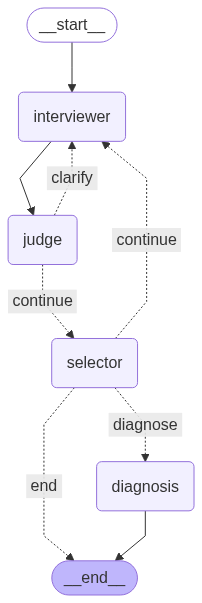

Enter session ID (or press Enter for new session):  1



Starting interview session: 1
Type 'quit' to end, 'history' to show past messages
--------------------------------------------------



You:  start


-----INVOKING------
enter interviewer
Do you feel anxious or uneasy in places or situations where help might not be available or escape difficult if you had a panic-like or embarrassing symptom, such as being in a crowd or queue, in an open space or crossing a bridge, in an enclosed space, when alone away from home, when alone at home, or traveling in a bus, train, car, or using public transportation? Please answer with yes or no, or if uncertain, feel free to explain.


You:  most of the time i feel anxious in these scenarios.


exit interviewer
enter judge
reason behind the decision: The patient's response directly addresses the question by indicating that they feel anxious in the specified scenarios. The intent is clear, and the response is complete and relevant. I am confident in classifying this response as a clear 'yes'.
decision: yes
exit judge
enter node selector
question_id: E1
branches: {'yes': 'E2', 'no': 'END_MODULE'}
raw judge label: yes
next question_id: E2
exit node selector
enter interviewer
Do these situations almost always bring on fear or anxiety? Please answer with yes or no, or if uncertain, feel free to explain.


You:  what is anxiety?


exit interviewer
enter judge
reason behind the decision: The patient's response does not directly address the question about whether situations bring on fear or anxiety. Instead, they are asking for clarification on what anxiety is, indicating a lack of understanding or uncertainty about the term. This response is ambiguous and does not provide a clear answer to the question.
decision: need more clarification
exit judge
enter interviewer
Do these situations almost always bring on fear or anxiety? Please answer with yes or no, or if uncertain, feel free to explain.


In [ ]:
run_interview_session(module_path="./mini_modules/working/module_e.json")